# Broader model search for Session 1

Reproduce with `python session1_robust_models.py`. Results and the selected forecast are saved in `results_robust/`. Previous forecasts remain in their original folders.

## What is new?
- Three SARIMA variants add seasonal moving-average terms or ordinary differencing.
- Hour-specific weather Ridge fits a separate daily shape and cloud response by hour, plus wind/weather effects, over 7–60 days.
- Weather correction anchors predictions to the last observed day, then adds the estimated weather-related change. Both future days reference known history.
- Residual boosting learns corrections to the 48-hour lag rather than fitting generation directly.
- Fixed-weight blends combine SARIMA with weather models. Blend weights are specified before evaluating this run, rather than optimized on each validation outcome.

No new packages or external datasets are needed. Hour/weather effects are modeling hypotheses, not claims about the underlying portfolio.

## Validation and decision rule
18 nonoverlapping 48-hour windows: six earliest blocks calibrate intervals, eleven later blocks select the lowest pooled RMSE under weather stress, and the latest block is a separate audit. This broadens selection by six earlier windows compared with our previous experiment. **Previously examined windows and the audit are not untouched tests.** More candidate searches can introduce selection optimism.

We repeat the observed-weather and three illustrative weather-error scenarios used before, with seeds tied to the forecast origin. Scenarios are sensitivity checks, not independent windows or measured weather-forecast uncertainty. Historical observed-weather scores are optimistic for weather-based models. We do not use actual future generation to construct features. Lagged targets are at least 48 hours old, and the correction models reference only the known last day.

Selection focuses on full 48-hour RMSE because the Session 1 baseline-beating criterion uses it. Day-two metrics are also shown because the final private leaderboard uses the second 24 hours. MAPE and Winkler can favor a different model. Only the instructor can score the hidden future.

Intervals for candidate models use the 95th percentile of earlier absolute rolling errors, separately for days one and two. Calibration stays fixed during validation, then uses all completed past blocks for the future forecast. They are nominal 95% intervals, without a future coverage guarantee.


In [ ]:
# Run from the repository root so data and results paths resolve.
import os, sys
from pathlib import Path
if Path.cwd().name == 'notebooks':
    os.chdir('..')
sys.path.insert(0, str(Path.cwd()))

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
out=Path("results_robust")
report=json.loads((out/"run_summary.json").read_text())
winner=report["selected_model"]
summary=pd.read_csv(out/"model_comparison.csv")
windows=pd.read_csv(out/"window_comparison.csv",parse_dates=["start","end"])
consistency=pd.read_csv(out/"window_consistency.csv")
SCENARIO="weather_stress"  # or "observed_weather"
selection=summary[(summary.phase=="selection")&(summary.scenario==SCENARIO)].sort_values("RMSE")
print("Selected model:",winner)
display(selection.set_index("model")[["RMSE","RMSE_ratio","MAPE","Winkler","coverage"]].round(3))


Selected model: blend_SARIMA50_hour50


,RMSE,RMSE_ratio,MAPE,Winkler,coverage
model,,,,,
blend_SARIMA50_hour50,277.105,0.871,355.026,1422.269,0.888
blend_SARIMA50_ridge50,282.335,0.887,364.907,1406.551,0.901
blend_three,283.680,0.892,391.233,1413.419,0.908
hour_weather_ridge_60d,290.563,0.913,546.565,1390.398,0.891
blend_SARIMA75_hour25,290.824,0.914,304.633,1436.968,0.917
blend_SARIMA50_correction50,291.356,0.916,313.696,1544.880,0.907
hour_weather_ridge_28d,291.605,0.917,542.864,1421.186,0.916
weather_boosting_60d,293.020,0.921,488.367,1401.856,0.908
blend_SARIMA75_ridge25,294.161,0.925,310.013,1493.630,0.908


## Does improvement persist across windows?
Below 1 beats seasonal naive. Win counts exclude the final audit. All 11 selection windows count once, despite repeated weather scenarios.

label,Oct 03,Oct 05,Oct 07,Oct 09,Oct 11,Oct 13,Oct 15,Oct 17,Oct 19,Oct 21,Oct 23,Oct 25 [audit]
model,,,,,,,,,,,,
blend_SARIMA50_hour50,0.89,1.02,0.92,1.08,0.58,0.99,0.75,0.65,0.70,1.00,1.14,1.35
blend_SARIMA50_ridge50,0.90,1.08,0.85,0.94,0.64,1.12,0.81,0.72,0.73,0.95,1.16,1.11
blend_three,0.84,1.13,0.85,1.04,0.61,1.04,0.81,0.71,0.79,0.92,1.09,1.23
hour_weather_ridge_60d,1.07,0.77,0.66,0.94,0.79,1.00,0.78,0.80,1.10,1.39,1.58,2.69
blend_SARIMA75_hour25,0.85,1.13,0.93,1.08,0.67,1.02,0.82,0.73,0.74,1.10,1.03,0.99
blend_SARIMA50_correction50,0.92,1.07,0.96,1.06,0.97,1.00,0.80,0.81,0.66,1.01,0.66,0.94
hour_weather_ridge_28d,1.25,0.74,0.71,0.96,0.74,1.05,0.81,0.78,1.14,1.08,1.38,2.37
weather_boosting_60d,1.12,0.85,0.63,1.05,0.98,1.16,0.79,0.78,0.80,1.21,1.58,2.04
blend_SARIMA75_ridge25,0.84,1.17,0.91,1.01,0.68,1.07,0.86,0.75,0.81,1.08,1.03,0.97


,windows,wins,mean_RMSE,median_RMSE_ratio,best_RMSE_ratio,worst_RMSE_ratio,mean_rank,win_rate
model,,,,,,,,
blend_SARIMA50_hour50,11,8,267.492,0.922,0.582,1.137,6.909,0.727
blend_SARIMA50_ridge50,11,8,273.175,0.901,0.642,1.162,8.364,0.727
blend_SARIMA50_correction50,11,8,279.156,0.963,0.660,1.068,9.364,0.727
residual_boosting_60d,11,8,289.124,0.952,0.683,1.209,11.000,0.727
weather_ridge_21d,11,8,299.372,0.890,0.761,1.538,11.091,0.727
blend_three,11,7,272.899,0.851,0.606,1.133,7.545,0.636
hour_weather_ridge_60d,11,7,287.845,0.945,0.661,1.575,9.727,0.636
SARIMA_21d,11,7,309.648,0.972,0.833,1.257,13.818,0.636
blend_SARIMA75_hour25,11,6,280.148,0.932,0.665,1.130,9.636,0.545


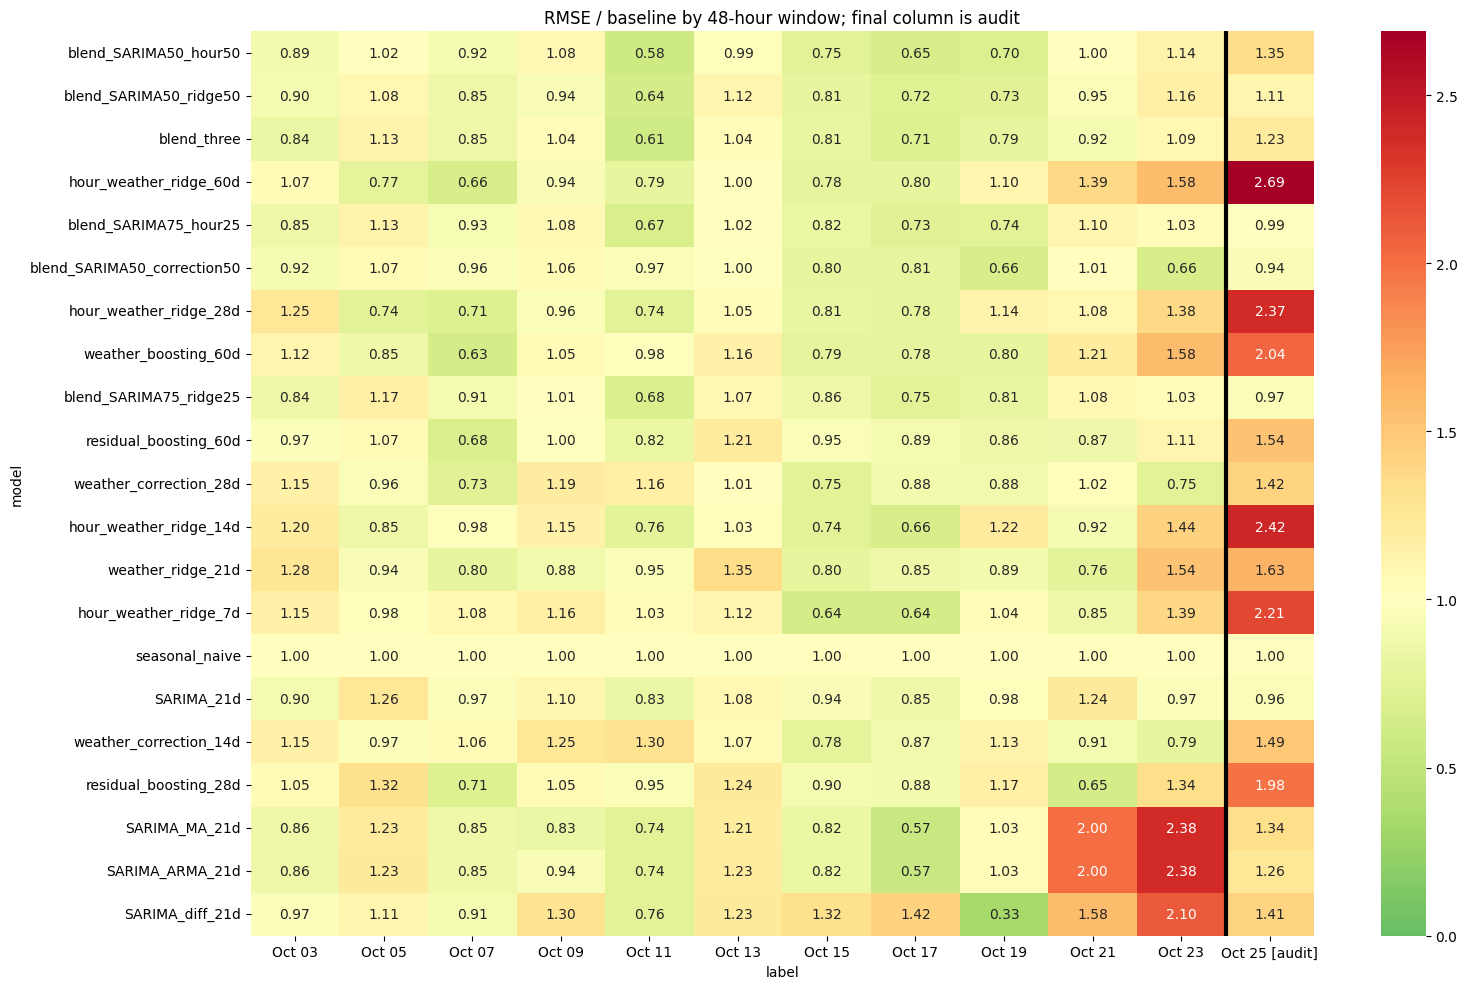

In [2]:
w=windows[windows.scenario==SCENARIO].copy()
w["label"]=w.start.dt.strftime("%b %d")+np.where(w.phase.eq("selection"),""," [audit]")
labels=w.sort_values("start").label.drop_duplicates().tolist()
ratios=w.pivot(index="model",columns="label",values="RMSE_ratio").reindex(index=selection.model,columns=labels)
display(ratios.round(2))
display(consistency[consistency.scenario==SCENARIO].set_index("model").drop(columns="scenario").round(3))
fig,ax=plt.subplots(figsize=(16,10))
sns.heatmap(ratios,annot=True,fmt=".2f",cmap="RdYlGn_r",center=1,vmin=0,vmax=max(2,float(ratios.max().max())),ax=ax)
ax.axvline(11,color="black",lw=3)
ax.set_title("RMSE / baseline by 48-hour window; final column is audit")
plt.tight_layout();fig.savefig(out/f"window_comparison_{SCENARIO}.png",dpi=150,bbox_inches="tight");plt.show()


## Recent versus earlier selection windows
The last five selection windows were previously used in our search. The six earlier windows broaden the comparison. These are descriptive subsets, not additional selection rules.

In [3]:
pred=pd.read_csv(out/"validation_predictions.csv",parse_dates=["ds"])
from session1_models import metrics
rows=[]
for label,folds in [("Earlier six",list(range(6,12))),("Recent five",list(range(12,17)))]:
    for model in list(dict.fromkeys([winner,"SARIMA_21d","weather_ridge_21d","seasonal_naive"])):
        g=pred[(pred.scenario==SCENARIO)&pred.fold.isin(folds)&(pred.model==model)]
        rows.append(dict(period=label,model=model,**metrics(g.actual.to_numpy(),g.forecast.to_numpy(),g.lower_95.to_numpy(),g.upper_95.to_numpy())))
display(pd.DataFrame(rows).set_index(["period","model"]).round(3))


RMSE     MAPE   Winkler  coverage  \
period      model                                                         
Earlier six blend_SARIMA50_hour50  305.226   62.489  1685.024     0.859   
            SARIMA_21d             340.017   62.938  1714.278     0.917   
            weather_ridge_21d      327.571   62.307  1861.552     0.856   
            seasonal_naive         322.407   82.055  2301.155     0.750   
Recent five blend_SARIMA50_hour50  239.032  706.070  1106.962     0.924   
            SARIMA_21d             295.532  490.494  1168.666     0.942   
            weather_ridge_21d      280.593  984.397  1135.777     0.922   
            seasonal_naive         312.953  765.279  2206.476     0.796   

                                   mean_width  
period      model                              
Earlier six blend_SARIMA50_hour50     864.682  
            SARIMA_21d               1092.756  
            weather_ridge_21d         890.220  
            seasonal_naive            701.717  
Recent five blend_SARIMA50_hour50     793.843  
            SARIMA_21d               1008.181  
            weather_ridge_21d         830.801  
            seasonal_naive            615.930

## Day two: relevant to the private leaderboard
These historical day-two scores do not reveal the hidden private leaderboard.

In [4]:
day2=pd.read_csv(out/"day_two_comparison.csv")
display(day2[day2.scenario==SCENARIO].sort_values("RMSE").set_index("model").drop(columns="scenario").round(3))


,RMSE,MAPE,Winkler,coverage,mean_width
model,,,,,
hour_weather_ridge_60d,276.532,249.509,1227.036,0.910,812.029
hour_weather_ridge_28d,276.629,242.887,1193.262,0.953,908.586
residual_boosting_60d,281.821,297.983,1238.417,0.938,975.921
hour_weather_ridge_14d,288.877,229.726,1406.258,0.907,825.637
weather_boosting_60d,289.131,296.853,1403.316,0.894,823.470
blend_SARIMA50_hour50,290.912,236.189,1593.711,0.851,763.895
weather_ridge_21d,293.100,251.910,1367.391,0.891,827.492
blend_SARIMA50_ridge50,296.128,248.538,1522.872,0.870,797.584
blend_three,296.828,257.169,1495.335,0.874,830.493


## Latest historical audit
Previously seen; excluded from model selection. Inspect whether a model that wins on average also works recently.

,RMSE,RMSE_ratio,MAPE,Winkler,coverage
model,,,,,
blend_SARIMA50_correction50,113.254,0.941,55.245,750.234,1.000
SARIMA_21d,116.108,0.964,38.789,904.063,1.000
blend_SARIMA75_ridge25,116.236,0.965,40.338,762.099,1.000
blend_SARIMA75_hour25,119.509,0.993,40.721,773.971,1.000
seasonal_naive,120.404,1.000,51.088,568.464,1.000
blend_SARIMA50_ridge50,133.105,1.105,50.878,752.642,1.000
blend_three,147.693,1.227,50.137,759.255,1.000
SARIMA_ARMA_21d,151.660,1.260,40.611,803.448,1.000
SARIMA_MA_21d,161.010,1.337,42.370,827.649,1.000


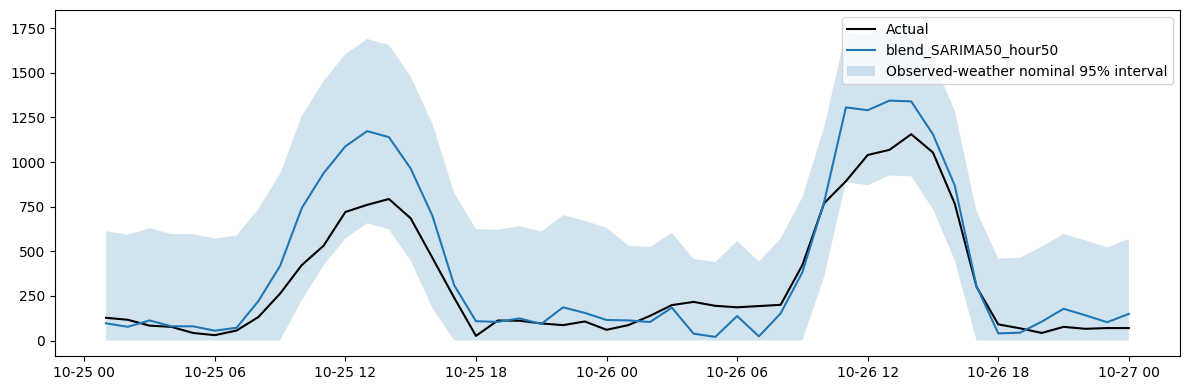

In [5]:
audit=summary[(summary.phase=="last_window_audit")&(summary.scenario==SCENARIO)]
display(audit.sort_values("RMSE").set_index("model")[["RMSE","RMSE_ratio","MAPE","Winkler","coverage"]].round(3))
g=pred[(pred.model==winner)&(pred.phase=="last_window_audit")&(pred.scenario=="observed_weather")]
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(g.ds,g.actual,label="Actual",color="black")
ax.plot(g.ds,g.forecast,label=winner)
ax.fill_between(g.ds,g.lower_95,g.upper_95,alpha=.2,label="Observed-weather nominal 95% interval")
ax.legend();plt.tight_layout();plt.show()


## Forecast ready for review
This uses supplied future weather without randomly perturbing the point forecast; uncertainty comes from past stress-scenario errors. The original SARIMA forecast is plotted for comparison.

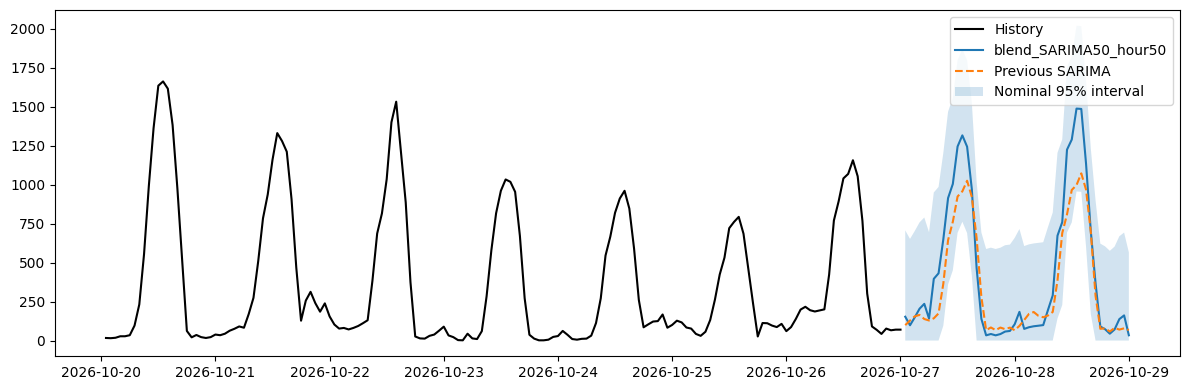

,ds,forecast,lower_95,upper_95
0,2026-10-27 01:00:00,152.750033,0.0,706.553598
1,2026-10-27 02:00:00,97.927367,0.0,651.730931
2,2026-10-27 03:00:00,148.769080,0.0,702.572644
3,2026-10-27 04:00:00,203.942277,0.0,757.745841
4,2026-10-27 05:00:00,235.283437,0.0,789.087002


In [6]:
data=pd.read_csv("train.csv",parse_dates=["ds"])
sub=pd.read_csv(out/"selected_model_forecast.csv",parse_dates=["ds"])
old=pd.read_csv("results/selected_model_forecast.csv",parse_dates=["ds"])
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(data.ds.iloc[-168:],data.y.iloc[-168:],label="History",color="black")
ax.plot(sub.ds,sub.forecast,label=winner)
ax.plot(old.ds,old.forecast,label="Previous SARIMA",linestyle="--")
ax.fill_between(sub.ds,sub.lower_95,sub.upper_95,alpha=.2,label="Nominal 95% interval")
ax.legend();plt.tight_layout();fig.savefig(out/"forecast.png",dpi=150,bbox_inches="tight");plt.show()
display(sub.head())


## Save the Moodle filename
Set your surname. This creates the submission file locally and does not upload it.

In [7]:
SURNAME=""
if SURNAME.strip():
    assert not any(c in SURNAME for c in "/\\")
    filename=f"{SURNAME.strip().upper()}_project.csv"
    pd.read_csv(out/"selected_model_forecast.csv").to_csv(filename,index=False)
    print("Saved",filename)
else:
    print("Set SURNAME to create the required Moodle filename.")


Set SURNAME to create the required Moodle filename.
